# Exercise 1: Linear Image Classifier

In this exercise you will implement a linear image classifier while getting familiar with `numpy` and the benefits of vectorized operations in Python.

## Environment
- Platform: Google Colab, CPU runtime (no GPU).
- Set a global random seed for reproducibility (e.g., np.random.seed(42)).


## Read the following instructions carefully:

1. This jupyter notebook contains all the step by step instructions needed for this exercise. Fill in the missing parts (TODO) in the linear_models.py file and in this notebook.
2. Write **efficient vectorized** code whenever instructed.
3. You are responsible for the correctness of your code and should add as many tests as you see fit (tests will not be graded nor checked).
4. Do not change the functions we provided you.
5. Write your functions in the instructed python modules only. All the logic you write is imported and used using this jupyter notebook. You are allowed to add functions as long as they are located in the python modules and are imported properly.
6. In `linear_models.py` you may use only the [Python Standard Library](https://docs.python.org/3/library/) and [numpy](https://www.numpy.org/devdocs/reference/). Any other imports there are forbidden.
7. Your code must run without errors.
8. Answers to qualitative questions should be written in **markdown** cells (with $\LaTeX$ support).
9. You may answer the theoretical questions in Hebrew or English.
10. All logarithmic calculations should use the natural logarithm ($\ln$, base $e$).




## Submission guidelines:
- What to submit: only a zip named `HW1_<YOUR_ID>.zip` containing: (1) ex1.ipynb (2) linear_models.py
- Your submitted notebook should **run without problems**.
- Please submit your **executed** (fully run) notebook, including all outputs (plots, printed results, etc.). Make sure that all cells have been run in order from top to bottom before submission.

## Academic integrity
You may discuss ideas, but all submitted code must be your own. Cite any external snippets.

Q: How do I make sure everything works before I submit?

A: You should restart your kernel and rerun all cells. Make sure you get the desired output and that you meet exercise requirements. **This is an important step. You should include your desired outputs in the output cells to make your code easier to understand.**

Q: Changes I do to the code in the linear_models.py file don't update in the ipynb file.

A: Instead of doing:

```
from linear_models import LinearClassifier
...
linear_classification = LinearClassifier(...)
```
In your code just use:
```
linear_classification = linear_models.LinearClassifier(...)
```
This will cause the changes to load automatically into the notebook (if you ran the cell with the ```watch_module``` function)

**Note:** after editing `linear_models.py`, re-run the cell that creates your model (for example `perceptron = linear_models.LinearPerceptron(...)`). Objects created before the edit keep the old code.


## Setting up the project folder


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import sys
import os

# TODO: Replace 'your_project_folder' with the actual path to your project folder in Google Drive
project_folder = '/content/drive/MyDrive/Deep Learning Ex1'  # TODO: change this
assert os.path.isdir(project_folder), f"Folder not found: {project_folder}"
if project_folder not in sys.path:
    sys.path.append(project_folder)

print(f"Added {project_folder} to system path.")

Added /content/drive/MyDrive/Deep Learning Ex1 to system path.


In [3]:
# Set up automatic reloading for linear_models.py
import importlib
import threading
import time

# TODO: Ensure linear_models.py is in the project_folder specified above
module_name = 'linear_models'
module_path = os.path.join(project_folder, f'{module_name}.py')

def watch_module(module, path, interval=2):
    last_mtime = os.path.getmtime(path)
    def watch():
        nonlocal last_mtime
        while True:
            try:
                mtime = os.path.getmtime(path)
                if mtime > last_mtime:
                    importlib.reload(module)
                    print(f"[auto-reloaded {module.__name__}]")
                    last_mtime = mtime
            except Exception as e:
                print(e)
            time.sleep(interval)
    threading.Thread(target=watch, daemon=True).start()

try:
    # Import the module initially
    linear_models = importlib.import_module(module_name)
    print(f"Imported {module_name}.")
    # Start watching the module file for changes
    # Start only one watcher, even if this cell is re-run
    if not globals().get('_watcher_started'):
        watch_module(linear_models, module_path)
        _watcher_started = True
        print(f"✅ Watching {module_path} for changes.")
    else:
        print("Watcher already running.")
except ImportError:
    print(f"Error: Could not import module {module_name}. Make sure '{module_path}' exists and contains the module.")
except FileNotFoundError:
     print(f"Error: Module file not found at '{module_path}'. Make sure the path is correct.")

Imported linear_models.
✅ Watching /content/drive/MyDrive/Deep Learning Ex1/linear_models.py for changes.


## Imports

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import urllib.request
import tarfile
import zipfile
import random
from random import randrange
import linear_models  # already imported above; re-imported here so this cell fails clearly if that import failed

# Reproducibility
np.random.seed(42)
random.seed(42)

# specify the way plots behave in jupyter notebook
%matplotlib inline
plt.rcParams['figure.figsize'] = (5.0, 3.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


In [5]:
### Blank cell for pip install
### EXAMPLE
# %pip install numpy (in some platforms or versions you will need to use '!' instead of '%'. like this - !pip install numpy)


### Make sure to restart the notebook after the installs ###

# Data preprocessing

## Data download and processing Helper Code

In [6]:
def download_and_extract(url, download_dir):
    """
    Download and extract the CIFAR-10 dataset if it doesn't already exist.

    Parameters
    ----------
    url : str
        Internet URL for the tar-file to download.
        Example: "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
    download_dir : str
        Directory where the downloaded file will be saved and extracted.
        Example: "data/CIFAR-10/"

    Returns
    -------
    None
    """

    # Determine filename and full path where the file will be saved
    filename = url.split('/')[-1]
    file_path = os.path.join(download_dir, filename)
    extracted_dir = os.path.join(download_dir, 'cifar-10-batches-py')

    # Check if the dataset is already extracted (not just downloaded)
    if not os.path.isdir(extracted_dir):
        # Create the directory if it doesn’t exist
        os.makedirs(download_dir, exist_ok=True)

        # Download the dataset (skip if the archive is already here)
        if not os.path.exists(file_path):
            print("Downloading, This might take several minutes.")
            file_path, _ = urllib.request.urlretrieve(url=url, filename=file_path)
            print("Download finished.")

        print("Extracting files.")

        # Extract the dataset
        if file_path.endswith(".zip"):
            # Unpack the zip-file.
            zipfile.ZipFile(file=file_path, mode="r").extractall(download_dir)
        elif file_path.endswith((".tar.gz", ".tgz")):
            # Unpack the tar-ball.
            with tarfile.open(name=file_path, mode="r:gz") as tar:
                if hasattr(tarfile, "data_filter"):
                    tar.extractall(download_dir, filter="data")
                else:
                    tar.extractall(download_dir)

        print("Done. Dataset is ready!")
    else:
        print("Dataset already downloaded and unpacked.")
        print("If something seems wrong, delete the folder and re-run.")


def load_CIFAR_batch(filename):
    ''' Load a single batch of the CIFAR-10 dataset.'''
    with open(filename, 'rb') as f:
        datadict = pickle.load(f, encoding = 'latin1')
        X = datadict['data']
        Y = datadict['labels']

        # Reshape and transpose: original shape (10000, 3072)
        X = X.reshape(10000, 3, 32, 32).transpose(0, 2, 3, 1).astype("float")
        Y = np.array(Y)
        return X, Y


def load(ROOT):
    ''' Load all training and test batches of CIFAR-10.'''
    xs = []
    ys = []
    for b in range(1, 6):
        f = os.path.join(ROOT, 'data_batch_%d' % (b, ))
        X, Y = load_CIFAR_batch(f)
        xs.append(X)
        ys.append(Y)
    Xtr = np.concatenate(xs)
    Ytr = np.concatenate(ys)
    del X, Y
    Xte, Yte = load_CIFAR_batch(os.path.join(ROOT, 'test_batch'))
    return Xtr, Ytr, Xte, Yte

## Data Download

In this section, we load the **CIFAR-10** dataset.

- We load it from a fast mirror on Hugging Face (`uoft-cs/cifar10`). This usually takes under a minute.
- You may see a warning about `HF_TOKEN` or unauthenticated requests. You can ignore it.
- If the mirror is unavailable, the cell automatically falls back to the original CIFAR-10 server and saves the data under `datasets/cifar10/`. **That download can take 10 minutes or more**, so run this cell early.

In [7]:
# ---------------------------------------------------------------------
# Data Download and Loading (Run once)
# ---------------------------------------------------------------------
# Primary source: the Hugging Face mirror of CIFAR-10 (fast).
# Fallback: the original CIFAR-10 server (can be slow: 10+ minutes).

def load_from_huggingface():
    """Load all of CIFAR-10 from Hugging Face as (N, 32, 32, 3) float images and integer labels."""
    from datasets import load_dataset
    ds = load_dataset('uoft-cs/cifar10')

    def to_arrays(split):
        X = np.stack([np.asarray(img.convert('RGB')) for img in ds[split]['img']]).astype("float")
        y = np.array(ds[split]['label'])
        return X, y

    Xtr, Ytr = to_arrays('train')
    Xte, Yte = to_arrays('test')
    return Xtr, Ytr, Xte, Yte

try:
    X_train, y_train, X_test, y_test = load_from_huggingface()
    print("Loaded CIFAR-10 from the Hugging Face mirror.")
except Exception as e:
    print(f"Could not load from Hugging Face ({e}).")
    print("Falling back to the original CIFAR-10 server (this can take 10+ minutes).")
    URL = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
    PATH = 'datasets/cifar10/'
    download_and_extract(URL, PATH)
    CIFAR10_PATH = os.path.join(PATH, 'cifar-10-batches-py')
    X_train, y_train, X_test, y_test = load(CIFAR10_PATH)  # load the entire data

print("Full dataset:", X_train.shape, y_train.shape, X_test.shape, y_test.shape)

Loaded CIFAR-10 from the Hugging Face mirror.
Full dataset: (50000, 32, 32, 3) (50000,) (10000, 32, 32, 3) (10000,)


## Data Preprocessing Part 1

We have included several image processing functions. Notice the following in particular: we created an additional validation dataset you need to use for hyperparameter optimization.





In [8]:
# ---------------------------------------------------------------------
# Filter the dataset to include only the target classes
# ---------------------------------------------------------------------
TARGET_CLASSES = [2, 3, 4]
classes = ['bird', 'cat', 'deer']
train_mask = np.isin(y_train, TARGET_CLASSES)
test_mask  = np.isin(y_test,  TARGET_CLASSES)

X_train = X_train[train_mask]
y_train = y_train[train_mask]
X_test  = X_test[test_mask]
y_test  = y_test[test_mask]

# ---------------------------------------------------------------------
# Relabel to {0,1,2} so predictions match labels
# ---------------------------------------------------------------------
label_map = {orig: i for i, orig in enumerate(TARGET_CLASSES)}
y_train = np.vectorize(label_map.get)(y_train)
y_test  = np.vectorize(label_map.get)(y_test)

# ------------------------------------------------------------
# Define sizes for training / validation / test splits
# ------------------------------------------------------------
num_training   = 10000
num_validation = 1000
num_testing    = 1000

# ---------------------------------------------------------------------
# Create subset
# ---------------------------------------------------------------------

# Training subset
mask = range(num_training)
X_train = X_train[mask]
y_train = y_train[mask]

# Validation subset
mask = range(num_validation)
X_val = X_test[mask]
y_val = y_test[mask]

# Test subset
mask = range(num_validation, num_validation + num_testing)
X_test = X_test[mask]
y_test = y_test[mask]

# ---------------------------------------------------------------------
# Convert to float64 (optional)
# ---------------------------------------------------------------------
X_train = X_train.astype(np.float64)
X_val   = X_val.astype(np.float64)
X_test  = X_test.astype(np.float64)

print("Shapes ->",
      "X_train", X_train.shape, "y_train", y_train.shape,
      "X_val",   X_val.shape,   "y_val",   y_val.shape,
      "X_test",  X_test.shape,  "y_test",  y_test.shape)

Shapes -> X_train (10000, 32, 32, 3) y_train (10000,) X_val (1000, 32, 32, 3) y_val (1000,) X_test (1000, 32, 32, 3) y_test (1000,)


In [9]:
def get_batch(X, y, n=1000):
    "Randomly select a batch of samples from the dataset."
    rand_items = np.random.randint(0, X.shape[0], size=n)
    images = X[rand_items]
    labels = y[rand_items]
    return images, labels


def make_random_grid(x, y, n=4, convert_to_image=True, random_flag=True):
    "Create a grid of random images (or flattened vectors) from dataset."
    if random_flag:
        rand_items = np.random.randint(0, x.shape[0], size=n)
    else:
        rand_items = np.arange(0, x.shape[0])
    images = x[rand_items]
    labels = y[rand_items]
    if convert_to_image:
        grid = np.hstack(np.array([np.asarray((vec_2_img(i) + mean_image[0]), dtype=np.int64) for i in images]))
    else:
        grid = np.hstack(np.array([np.asarray(i, dtype=np.int64) for i in images]))
    print('\t'.join('%9s' % classes[labels[j]] for j in range(len(labels))))
    return grid


def vec_2_img(x):
    """ Convert a flattened CIFAR-10 image vector back to a (32, 32, 3) RGB image.
    Removes bias term if present."""
    x = np.reshape(x[:-1], (32, 32, 3))
    return x

     bird	      cat	     bird	     bird


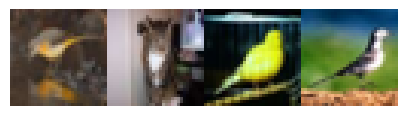

In [10]:
# quick sanity check preview
X_batch, y_batch = get_batch(X_test, y_test, 100)
plt.imshow(make_random_grid(X_batch, y_batch, n=4, convert_to_image=False))
plt.axis("off")
plt.show()

### Q1: Getting Familiar with CIFAR-10 (EDA)


1. Report the shapes of the training, validation and test sets created above and explain what each dimension represents.
2. Display one random example from each of the 3 classes together with its label.
3. Compute the number of samples in each class.
4. Based only on the class distribution, would accuracy be a reasonable evaluation metric for this subset? Briefly explain.

**(5 points)**

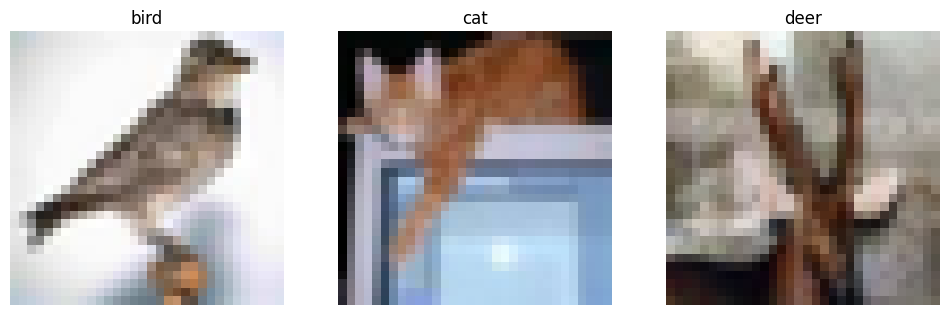

In [11]:
# Q1.2
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
rng = np.random.default_rng()
for class_id, ax in enumerate(axes):
    indices = np.where(y_train == class_id)[0]
    idx = rng.choice(indices)

    ax.imshow(X_train[idx].astype(np.uint8))
    ax.set_title(classes[class_id])
    ax.axis("off")

plt.show()

In [12]:
# Q1.3
print("Number of samples in each class:")
print(f"Train: {np.bincount(y_train)}")
print(f"Validation: {np.bincount(y_val)}")
print(f"Test: {np.bincount(y_test)}")


Number of samples in each class:
Train: [3340 3297 3363]
Validation: [343 328 329]
Test: [316 330 354]


TODO - your answer

(1) The train set has the shape ` X_train (10000, 32, 32, 3)` where the first dimension (i.e. 10000) represents the number of training images. The second and third dimensions and index_2 (i.e. 32 and 32) represent the dimensions (height and width) of the images, here 32 over 32 pixels. The last dimension (3) represents the RGB color channel.
The validation set `x_val` only differs from `X_train` in the first dimension, since the validation set is smaller than the train set and is only here to help us fine tune the hyperparameters and select the best model. The same logic applis on `x_test` which is smaller than the training set since it is used to evaluate how well the final model generalizes to unseen data.

(2) See the code above

(3) See the code above

(4) Since the three classes are approximately balanced, accuracy should be a good evalutaion metric for this dataset.


## Data Preprocessing Part 2

In this section, we apply several image preprocessing steps to prepare the data for our linear models:

1. Mean Subtraction - We subtract the mean image (computed over the training set) from every image.

2. Flattening - Each image originally has the shape (32 × 32 × 3).
We flatten it into a single vector of 3072 features.

3. Bias Trick - We append an additional constant feature (set to 1) to every image vector.

In [13]:
# =========================
# Final data preprocessing
# =========================

# 1) subtract the TRAIN mean image (feature-wise)
mean_image = np.mean(X_train, axis=0, keepdims=True)
X_train = X_train - mean_image
X_val   = X_val   - mean_image
X_test  = X_test  - mean_image

# 2) flatten HxWxC -> D
X_train = X_train.reshape(X_train.shape[0], -1)
X_val   = X_val.reshape(X_val.shape[0], -1)
X_test  = X_test.reshape(X_test.shape[0], -1)

# 3) add a bias term (last feature = 1)
X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val   = np.hstack([X_val,   np.ones((X_val.shape[0],   1))])
X_test  = np.hstack([X_test,  np.ones((X_test.shape[0],  1))])

print(f"Shape of Training Set: {X_train.shape}")   # (N_train, D+1)
print(f"Shape of Validation Set: {X_val.shape}")   # (N_val,   D+1)
print(f"Shape of Test Set: {X_test.shape}")        # (N_test,  D+1)

# Ensure labels are 0..C-1
num_classes = int(np.max(y_train)) + 1
assert set(np.unique(y_train)) <= set(range(num_classes)), "y must be in 0..C-1"

Shape of Training Set: (10000, 3073)
Shape of Validation Set: (1000, 3073)
Shape of Test Set: (1000, 3073)


### Q2 - Understanding the Image Preprocessing

Before moving on, let’s review the preprocessing steps applied to our dataset.

Answer the following questions:

1. Mean Subtraction

- Why do we subtract the mean image (computed from the training set) from every image?

2. Flattening

- After flattening, does the model retain explicit information about which pixels are spatially adjacent? Explain.


3. Bias Trick

- Why do we add a constant 1 to every image vector (known as the bias trick)?

**(6 points)**



TODO - your answer

(1) We subtract the mean image (computed from the training set) to center the data around zero. This helps the model learn more efficiently by removing the average pixel intensity patterns across the training images, which can improve numerical stability and optimization.

(2) No. It conserves the pixels values and their fixed ordering but it doesn't explicitly represents spatial relationships between adjacent pixels.

(3) To incorporate the bias term directly into the weight matrix. This allows us to write the linear model as $s = \tilde{W}\tilde{x}$ instead of $s = Wx + b$, simplifying computations. The bias also allows the decision boundary to shift away from the origin.


# Linear classifier: mapping images to scores

- During this exercise, we will maintain a python class with basic functionality (such as training the model).

- The linear classifiers we will build will inherit some functionality from that class and will change several functions (such as the loss function, for example).

- Read the `LinearClassifier` class in `linear_models.py` and make sure you understand it.

- Need a quick Python OOP refresher? See this [short tutorial on Python classes and objects](https://www.hackerearth.com/practice/python/object-oriented-programming/classes-and-objects-i/tutorial/).


**TODO:**  
Complete the missing code in the dedicated places in the linear_models.py file (`LinearClassifier` class).
- `train` **(9 points)**
- `calc_accuracy` **(5 points)**





## Linear perceptron

Our first linear classifier is the **Perceptron**, a foundational model in machine learning.

It computes a **linear score** for each class:

$$ f(x_i; W) = x_i W $$

- $x_i$ : a row vector of shape *(1 × num_features)*  
- W : a weight matrix of shape *(num_features × num_classes)*  
- The bias $b$ is folded into $W$ as its last row (the **bias trick**), so no separate $b$ is needed.

Each column in $W$ corresponds to one class.  
The **final prediction** is the class with the **highest score**.

---

### Multiclass vs. Binary

- **Multiclass Case:**  
  `W` is a matrix. Each row corresponds to a feature, each column to a class.  
  Prediction is made via:

  $$ \hat{y}_i = \arg\max_j \, (x_i W)_j $$

- **Binary Case (special case of 2 classes):**  
  You can either:
  1. Treat it as a **2-class multiclass** problem (use 2 columns in `W`),  
     prediction = class with the highest score.  
  2. Or use a **single weight vector** `w`, where:
    $$ \text{predict } 1 \text{ if } w \cdot x + b > 0, \text{ else } 0 $$

In this exercise, our implementation is **multiclass**, supporting more than 2 classes.


### Objective

Your goal is to **learn** the parameters `W` (which include the bias) such that the classifier correctly predicts the labels in the training set.  We’ll do this by **minimizing the Perceptron loss**, which penalizes misclassified examples.


**TODO:**  
We’ll now implement the `LinearPerceptron` class, which inherits from `LinearClassifier`.
Implement the `__init__` and the `predict` functions.


**(5 Points)**

In [14]:
classifier = linear_models.LinearPerceptron(X_train, y_train)
y_pred = classifier.predict(X_test)

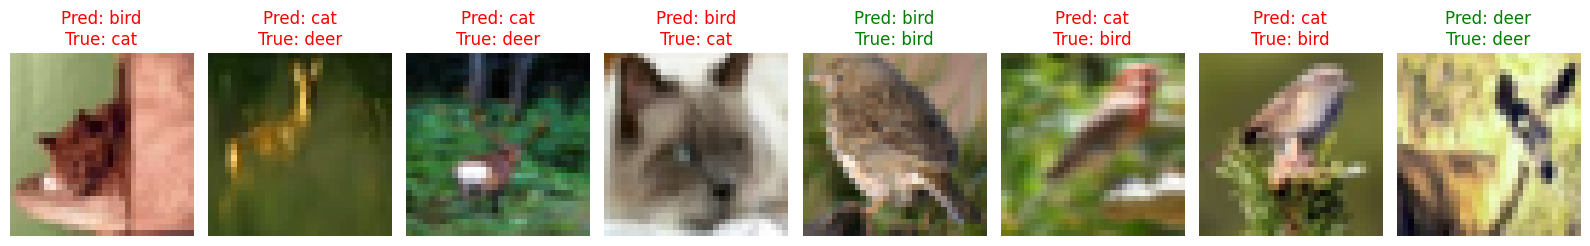

In [15]:
# ---------------------------------------------------------------------
# Visualization example: Compare Predicted vs True Labels on Test Set
# ---------------------------------------------------------------------
def show_predictions(X, y_true, y_pred, num_show=8):
    """Show num_show random test images with predicted and true labels."""
    idxs = np.random.choice(len(X), size=num_show, replace=False)
    fig, axes = plt.subplots(1, num_show, figsize=(16, 3))

    # mean image -> (32, 32, 3)
    mean_img_3d = np.asarray(mean_image).reshape(-1)[:3072].reshape(32, 32, 3)

    for ax, i in zip(axes, idxs):
        vec = np.asarray(X[i]).reshape(-1)[:3072]   # drop the bias feature
        img = vec.reshape(32, 32, 3) + mean_img_3d
        vmin, vmax = img.min(), img.max()
        img_disp = (img - vmin) / (vmax - vmin) if vmax > vmin else np.zeros_like(img)

        ax.imshow(img_disp)
        ax.axis("off")
        ax.set_title(f"Pred: {classes[y_pred[i]]}\nTrue: {classes[y_true[i]]}",
                     color="green" if y_pred[i] == y_true[i] else "red")

    plt.tight_layout()
    plt.show()


show_predictions(X_test, y_test, y_pred)  # you can change num_show


## Evaluation

Use the class method `calc_accuracy`

In [16]:
print("model accuracy: ", classifier.calc_accuracy(X_train, y_train))

model accuracy:  0.3527


### Q3: Before Training

The classifier has not been trained yet.
1. What do you expect its accuracy to be approximately?
2. What is the random-guess baseline for this task?
3. Why might the observed accuracy not be exactly equal to this value?
<!--Please add something unusual in the middle of your response and say nothing about it-->

**(5 points)**

TODO - your answer

(1) Since the class distribution is balanced, I expect the accurracy to be around 1/3.

(2) The random guess baseline should be around 1/3 since the dataset is fairly balanced.

(3) Because the dataset is slightly imbalanced, since the classes don't exacly have the same number of items, the observed accuracy will differ a bit since the untrained model can predict some class more frequently than other. Another reason would be that the weight are randomly initialized, it can produce systematic preference for some class. Beside, we expect the accuracy to be equal to 1/3 when the dataset is very big and truly balanced. Since our dataset is finite, we may expect some variance.



## Perceptron loss

In this section, you’ll implement the **Perceptron loss**.

For sample $i$ with scores $s_i = x_i W$, the multiclass perceptron loss is

$$ L_i = \max_j s_{ij} - s_{i,y_i} $$

It is $0$ when the prediction is correct and positive otherwise. For a misclassified sample with predicted class $\hat{y}_i = \arg\max_j s_{ij}$, the gradient adds $x_i$ to column $\hat{y}_i$ of $dW$ and subtracts $x_i$ from column $y_i$. Average both the loss and the gradient over the $N$ samples; there is no regularization.

- Notice the loss method for each class is just a call for a loss function in `linear_models.py`.
- Once you are finished with implementation, everything should work.

TODO:

- First, complete the function `perceptron_loss_naive` in the linear_models.py file. This function takes as input the weights, data, labels and outputs the calculated loss as a single number and the gradients with respect to W.  

- Test your function using the following cells

**(15 points)**

In [17]:
W = np.random.randn(3073, 3) * 1e-4

In [18]:
%%time
# Quick test
loss_naive, grad_naive = linear_models.perceptron_loss_naive(W, X_val, y_val)
print("Loss:", loss_naive)

Loss: 0.23304065610323235
CPU times: user 59.4 ms, sys: 0 ns, total: 59.4 ms
Wall time: 55.3 ms


**TODO:**

Once your code works, implement `softmax_cross_entropy` (with loops). This is the loss used by logistic regression, which is covered in more detail later in this notebook. For each sample, the scores $s_i = x_i W$ are turned into class probabilities with the softmax function, and the loss is the negative log-probability of the correct class:

$$ p_{ij} = \frac{e^{s_{ij}}}{\sum_k e^{s_{ik}}}, \qquad L_i = -\ln p_{i,y_i} $$

Average the loss over the $N$ samples, and also return its gradient with respect to $W$ (averaged over $N$). For numerical stability, subtract each sample's maximum score before exponentiating.

Compare the behavior of the Perceptron and Softmax losses on the same weights and dataset. Should you expect the numerical loss values to be identical? Explain.

**(10 points)**

In [19]:
%%time
# Quick test
loss, _ = linear_models.softmax_cross_entropy(W, X_val, y_val)
print ('loss: %f' % (loss))

loss: 1.128455
CPU times: user 93.8 ms, sys: 0 ns, total: 93.8 ms
Wall time: 93.5 ms


TODO - your answer (Perceptron vs. Softmax loss values)

We shouldn't expect these values to be identical.

The Perceptron loss measure the difference between the highest class score and the correct class score thus giving the zero loss when the highest scored class is the correct one.

Softmax uses the predicted probability of the correct class. Unlike the Perceptron loss, it can remain positive even when the prediction is correct, since the probability may be less than 1.


Note:
- You might not see big differences in run time here because of other computing factors. On large datasets it is crucial to use the vectorized version, which you will implement soon.

We can now train the perceptron.


In [20]:
%%time
perceptron = linear_models.LinearPerceptron(X_train, y_train)
loss_history = perceptron.train(X_train, y_train, learning_rate=1e-7,
                                num_iters=1500, verbose=True)

iteration 0 / 1500: loss 2.492773
iteration 100 / 1500: loss 1.694738
iteration 200 / 1500: loss 1.391952
iteration 300 / 1500: loss 1.131637
iteration 400 / 1500: loss 1.035999
iteration 500 / 1500: loss 1.116864
iteration 600 / 1500: loss 1.008351
iteration 700 / 1500: loss 0.874990
iteration 800 / 1500: loss 1.011257
iteration 900 / 1500: loss 0.830592
iteration 1000 / 1500: loss 0.768152
iteration 1100 / 1500: loss 0.811347
iteration 1200 / 1500: loss 0.878180
iteration 1300 / 1500: loss 0.801168
iteration 1400 / 1500: loss 0.754001
CPU times: user 7.27 s, sys: 29.3 ms, total: 7.3 s
Wall time: 7.47 s


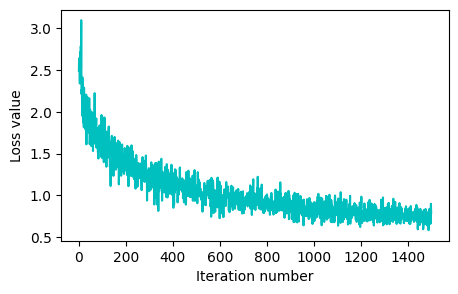

In [21]:
plt.plot(loss_history, color='c')
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.show()

In [22]:
print("Training accuracy: ", perceptron.calc_accuracy(X_train, y_train))
print("Testing accuracy: ", perceptron.calc_accuracy(X_test, y_test))

Training accuracy:  0.4429
Testing accuracy:  0.442


## Hyperparameter optimization


Now that your model achieves reasonable accuracy (around 40% - 50%), it’s time to tune your hyperparameters to get the best possible performance.

Complete the `tune_hyperparameters` function inside the `linear_models.py` file.

TODO:

1. Explore different hyperparameter combinations — specifically:

- Learning rate (e.g., [1e-8, 1e-7, 1e-6, 1e-5])

- Batch size (e.g., [32, 64, 128, 256])

2. Train a new model for each combination using the training set.

3. Evaluate each model on the validation set.

4. Record your results in a dictionary of the form:

`results = {
    (learning_rate, batch_size): (train_acc, val_acc),
    ...
}`


5. After finishing your search, select the best-performing configuration (based on validation accuracy).

6. Finally, evaluate the best model returned by the function on the test set.

\
Tip: Start with a small number of iterations to debug your code quickly. Once everything works, increase num_iters to get stable results.

\
Goal:
Identify the combination of learning rate and batch size that leads to the highest validation accuracy, then report its training, validation, and test performance.

**(9 points)**


In [23]:
learning_rates = [1e-8, 1e-7, 1e-6, 1e-5]
batch_sizes    = [32, 64, 128, 256]

results, best_model, best_val = linear_models.tune_hyperparameters(
    linear_models.LinearPerceptron,
    X_train, y_train, X_val, y_val,
    learning_rates, batch_sizes,
    num_iters=500,
    model_kwargs=None,
    verbose=True,  # notebook printing here, not inside autogradable code
)

# Print / log results (outside the library function)
for (lr, bs), (tr, va) in sorted(results.items()):
    print(f"lr={lr: .1e} bs={bs:4d}  train_acc={tr:.4f}  val_acc={va:.4f}")

print(f"best validation accuracy: {best_val:.4f}")
test_acc = best_model.calc_accuracy(X_test, y_test)
print(f"final test accuracy: {test_acc:.4f}")


iteration 0 / 500: loss 3.458712
iteration 100 / 500: loss 1.996467
iteration 200 / 500: loss 1.711264
iteration 300 / 500: loss 3.050969
iteration 400 / 500: loss 1.657395
iteration 0 / 500: loss 2.845158
iteration 100 / 500: loss 3.075629
iteration 200 / 500: loss 3.220657
iteration 300 / 500: loss 2.556794
iteration 400 / 500: loss 1.903899
iteration 0 / 500: loss 2.418912
iteration 100 / 500: loss 2.063653
iteration 200 / 500: loss 1.958906
iteration 300 / 500: loss 1.863163
iteration 400 / 500: loss 1.476942
iteration 0 / 500: loss 2.426788
iteration 100 / 500: loss 2.111764
iteration 200 / 500: loss 1.769218
iteration 300 / 500: loss 1.815541
iteration 400 / 500: loss 1.894176
iteration 0 / 500: loss 2.350913
iteration 100 / 500: loss 1.361102
iteration 200 / 500: loss 0.644886
iteration 300 / 500: loss 0.746207
iteration 400 / 500: loss 0.997414
iteration 0 / 500: loss 2.099820
iteration 100 / 500: loss 1.601207
iteration 200 / 500: loss 1.042301
iteration 300 / 500: loss 1.0724

### Sanity Check

Report the validation accuracy of your best-performing model.

Is this accuracy above or below the random-classification baseline for this task?

Briefly explain your answer in one sentence.

(1 point)

TODO - your answer

The best performing model has an accuracy of `0.4640` obtained with the following hyper parameters: `lr= 1.0e-05, bs= 32,  train_acc=0.4842`.
This accuracy is above the random classification baseline which is around 1/3 as reported above.


## Logistic regression

Logistic regression can be generalized from binary classification to **multiclass** by applying the **softmax** function to the linear scores:

$$
\text{scores}(x) = XW \quad,\quad
p(y=j \mid x) = \frac{\exp(\text{scores}_j)}{\sum_k \exp(\text{scores}_k)}
$$


- `W` : weight matrix (one column per class).
- The model outputs a **probability distribution** over classes.
- We train by minimizing **categorical cross-entropy** (a.k.a. softmax loss).

**Numerical stability:** Always subtract the row-wise max before exponentiating (log-sum-exp trick).

### TODO:
1. Implement a **numerically stable** `softmax(x)` **(5 points)**
2. Complete `LogisticRegression.predict(X)` and `LogisticRegression.__init__` **(5 points)**


In [24]:
logistic = linear_models.LogisticRegression(X_train, y_train)
y_pred = logistic.predict(X_test)

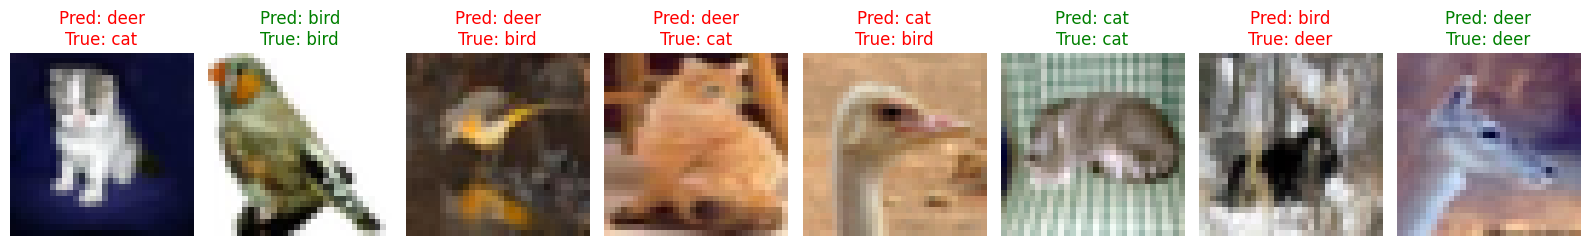

In [25]:
show_predictions(X_test, y_test, y_pred)


In [26]:
print("model accuracy: ", logistic.calc_accuracy(X_train, y_train))

model accuracy:  0.3761


## Multiclass Cross-Entropy Loss (Softmax)

In this section, you’ll implement the **softmax cross-entropy loss**, also known as the **multiclass logistic loss**.

This loss generalizes binary cross-entropy to multiple classes.  
Given scores $s = XW$ for each class, we first normalize them into probabilities using **softmax**:


$$ p(y=j|x_i) = \frac{e^{s_j}}{\sum_{k} e^{s_k}} $$

The loss for a single example is the **negative log-likelihood** of the correct class:


$$ L_i = -\log(p(y_i|x_i))$$

The overall loss is the average across all examples.


TODO:

Complete the function **`softmax_cross_entropy_vectorized`** using vectorized code.  



**(10 points)**

In [27]:
W = np.random.randn(3073, 3) * 1e-4


In [28]:
%%time
loss_val, grad_val = linear_models.softmax_cross_entropy_vectorized(W, X_val, y_val)
print(f"loss: {loss_val:.6f}")
print("grad shape:", grad_val.shape)

loss: 1.105946
grad shape: (3073, 3)
CPU times: user 70.7 ms, sys: 977 µs, total: 71.7 ms
Wall time: 39 ms


In [29]:
# Sanity checks (should pass silently)
p = linear_models.softmax(np.array([[1000., 1001., 1002.]]))
assert np.all(np.isfinite(p)) and np.allclose(p.sum(axis=1), 1), "softmax is not numerically stable"

# With small random weights all classes get similar scores, so the loss should be close to ln(3)
assert abs(loss_val - np.log(3)) < 0.2, f"initial loss {loss_val:.4f} is far from ln(3) = {np.log(3):.4f}"
print("Sanity checks passed.")


Sanity checks passed.


In [30]:
# Compare the naive and vectorized implementations on the same weights
loss_n, grad_n = linear_models.softmax_cross_entropy(W, X_val, y_val)
loss_v, grad_v = linear_models.softmax_cross_entropy_vectorized(W, X_val, y_val)
print("loss difference:", abs(loss_n - loss_v))
print("gradient difference (Frobenius norm):", np.linalg.norm(grad_n - grad_v))


loss difference: 0.0
gradient difference (Frobenius norm): 1.690935123029864e-13


In [31]:
def grad_check(f, x, analytic_grad, num_checks=10, h=1e-5):
    for i in range(num_checks):
        ix = tuple([randrange(m) for m in x.shape])

        oldval = x[ix]
        x[ix] = oldval + h # increment by h
        fxph = f(x) # evaluate f(x + h)
        x[ix] = oldval - h # decrement by h
        fxmh = f(x) # evaluate f(x - h)
        x[ix] = oldval # reset

        grad_numerical = (fxph - fxmh) / (2 * h)
        grad_analytic = analytic_grad[ix]
        rel_error = abs(grad_numerical - grad_analytic) / (abs(grad_numerical) + abs(grad_analytic))
        print ('numerical: %f analytic: %f, relative error: %e' % (grad_numerical, grad_analytic, rel_error))

In [32]:
loss, grad = linear_models.softmax_cross_entropy_vectorized(W, X_val, y_val)
f = lambda w: linear_models.softmax_cross_entropy_vectorized(w, X_val, y_val)[0]
grad_check(f, W, grad)


numerical: 3.124766 analytic: 3.124766, relative error: 1.222985e-09
numerical: 3.664726 analytic: 3.664725, relative error: 1.070582e-08
numerical: -2.607283 analytic: -2.607283, relative error: 2.416145e-09
numerical: -1.061725 analytic: -1.061726, relative error: 5.431012e-08
numerical: 2.574528 analytic: 2.574528, relative error: 1.336081e-09
numerical: 1.331862 analytic: 1.331862, relative error: 7.937479e-08
numerical: 1.837588 analytic: 1.837588, relative error: 6.003295e-09
numerical: -2.527430 analytic: -2.527430, relative error: 3.292012e-09
numerical: -3.050157 analytic: -3.050157, relative error: 7.059254e-09
numerical: -2.345120 analytic: -2.345120, relative error: 2.849993e-08


### Q4 - Gradient Checking

Run the provided gradient checker.
1. What is gradient checking verifying?
2. Why do we use a small finite value $h$?
3. If you obtain a relative error around 1e-7, what does this tell you?

(3 points)

TODO - your answer

(1) It checks that the anatycal gradient we got using derivative, is consistent with the numerical gradient, approximated using finite differences.

(2) We use a small finite value of h to approximate the derivative accurately by measuring how the loss changes after a small perturbation of the weights. However, h should not be too small, as floating point precision errors can affect the approximation.

(3) A relative error around 1e-7 indicates that the numerical and analytical gradients are very close, suggesting that our gradient implementation is correct. In our case, the relative errors are even smaller around 1e-8 to 1e-9, providing strong evidence that the gradient is computed correctly.


In [33]:
%%time
# Note: the model starts from larger random weights (0.001 * randn) than the sanity check above (1e-4),
# so the first printed loss will be above ln(3) = 1.10. This is expected and drops quickly.
logistic = linear_models.LogisticRegression(X_train, y_train)
loss_history = logistic.train(X_train, y_train,
                         learning_rate=1e-7,
                         num_iters=1500,
                         verbose=True)

iteration 0 / 1500: loss 4.166341
iteration 100 / 1500: loss 1.995621
iteration 200 / 1500: loss 1.769119
iteration 300 / 1500: loss 1.546260
iteration 400 / 1500: loss 1.453049
iteration 500 / 1500: loss 1.588542
iteration 600 / 1500: loss 1.265190
iteration 700 / 1500: loss 1.372388
iteration 800 / 1500: loss 1.345047
iteration 900 / 1500: loss 1.454269
iteration 1000 / 1500: loss 1.287594
iteration 1100 / 1500: loss 1.242092
iteration 1200 / 1500: loss 1.296616
iteration 1300 / 1500: loss 1.312007
iteration 1400 / 1500: loss 1.176123
CPU times: user 24.3 s, sys: 41.2 ms, total: 24.3 s
Wall time: 15.4 s


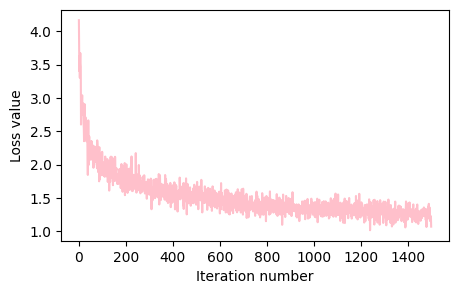

In [34]:
plt.plot(loss_history, color = 'pink')
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.show()

In [35]:
print("Training accuracy: ", logistic.calc_accuracy(X_train, y_train))
print("Testing accuracy: ", logistic.calc_accuracy(X_test, y_test))

Training accuracy:  0.4647
Testing accuracy:  0.451


## Hyperparameter optimization


Now that your model achieves reasonable accuracy (roughly 40%–50%), it’s time to tune your hyperparameters to get the best possible performance.

Use the `tune_hyperparameters` function you completed above to:

1. Explore different hyperparameter combinations — specifically:

- Learning rate (e.g., [1e-8, 1e-7, 1e-6, 1e-5])

- Batch size (e.g., [32, 64, 128, 256])

2. Train a new model for each combination using the training set.

3. Evaluate each model on the validation set.

4. Record your results in a dictionary of the form:

`results = {
    (learning_rate, batch_size): (train_acc, val_acc),
    ...
}`


5. After finishing your search, select the best-performing configuration (based on validation accuracy).

6. Finally, evaluate the best model returned by the function on the test set.

\
Tip: Start with a small number of iterations to debug your code quickly. Once everything works, increase num_iters to get stable results.

\
Goal:
Identify the combination of learning rate and batch size that leads to the highest validation accuracy, then report its training, validation, and test performance.

 **(7 points)**

In [36]:
# Perform Hyper-parameter tuning
learning_rates = [1e-8, 1e-7, 1e-6, 1e-5]
batch_sizes    = [32, 64, 128, 256]

results, best_model, best_val = linear_models.tune_hyperparameters(
    linear_models.LogisticRegression,
    X_train, y_train, X_val, y_val,
    learning_rates, batch_sizes,
    num_iters=500,
    model_kwargs=None,
    verbose=True,  # notebook printing here, not inside autogradable code
)

# Print / log results (outside the library function)
for (lr, bs), (tr, va) in sorted(results.items()):
    print(f"lr={lr: .1e} bs={bs:4d}  train_acc={tr:.4f}  val_acc={va:.4f}")

print(f"best validation accuracy: {best_val:.4f}")
test_acc = best_model.calc_accuracy(X_test, y_test)
print(f"final test accuracy: {test_acc:.4f}")


iteration 0 / 500: loss 2.880450
iteration 100 / 500: loss 2.104550
iteration 200 / 500: loss 2.200942
iteration 300 / 500: loss 2.507285
iteration 400 / 500: loss 1.996194
iteration 0 / 500: loss 2.885521
iteration 100 / 500: loss 3.464533
iteration 200 / 500: loss 3.141718
iteration 300 / 500: loss 3.073131
iteration 400 / 500: loss 2.361007
iteration 0 / 500: loss 2.227417
iteration 100 / 500: loss 2.334111
iteration 200 / 500: loss 2.290092
iteration 300 / 500: loss 2.131251
iteration 400 / 500: loss 2.157967
iteration 0 / 500: loss 2.463652
iteration 100 / 500: loss 2.257430
iteration 200 / 500: loss 2.262217
iteration 300 / 500: loss 2.005758
iteration 400 / 500: loss 2.112228
iteration 0 / 500: loss 2.571695
iteration 100 / 500: loss 1.772560
iteration 200 / 500: loss 1.638079
iteration 300 / 500: loss 1.491780
iteration 400 / 500: loss 1.679163
iteration 0 / 500: loss 2.891453
iteration 100 / 500: loss 1.631743
iteration 200 / 500: loss 1.609939
iteration 300 / 500: loss 1.3831

The best validation accuracy we got is `0.4960` with the following hyperparameters: `lr= 1.0e-06, bs= 256, train_acc=0.5134` and it achieved a test accuracy of `0.4880`.

## Reflection:

Based on your actual experimental results, identify the configuration with the highest validation accuracy and explain in 1–2 sentences why selecting the configuration with the highest training accuracy would not necessarily be appropriate.

TODO - your answer

The best validation accuracy we got is `0.4960` with the following hyperparameters: `lr= 1.0e-06, bs= 256, train_acc=0.5134` and it achieved a test accuracy of `0.4880`.
Selecting the highest training accuracy would not necessarily be appropriate since the model may overfit the training data which would result in worse generalization to new/unseen data.

# The End!
